In [2]:
import json, os, sys
import os.path as osp
from pathlib import Path

import imageio.v3 as imageio
import mediapy
import numpy as np

sys.path.insert(0, osp.abspath('..'))
from utils import apply_anno, generate_rand_colors, rle_to_bmask

# TODO: update with your path
frame_dir = '../OmniST/JPEGImages'
anno_dir = '../OmniST/Annotations'
color_map = generate_rand_colors(20, seed=10)[np.newaxis, :, :] / 255.

In [3]:
def visualize_gt(instance, event_idxs=None, include_first_frame=False, color_idxs=None):
    # Load frames
    folder = osp.join(frame_dir, instance)
    paths = sorted(osp.join(folder, x) for x in os.listdir(folder) if x.endswith('.jpg'))
    if not paths:
        raise FileNotFoundError(f'No .jpg frames found under {folder}')

    # Load annotations
    anno_path = osp.join(anno_dir, f'{instance}_annotations.json')
    trans_path = osp.join(anno_dir, f'{instance}_transformations.json')
    with open(anno_path, 'r') as f:
        annotations = json.load(f)
    with open(trans_path, 'r') as f:
        events = sorted(json.load(f), key=lambda e: int(e['start_frame']))

    # Keep only the requested events from event_idxs
    if event_idxs is not None:
        events = [events[i] for i in event_idxs]

    all_objs = []
    for event in events:
        for obj in event['start_state_objects'] + event['end_state_objects']:
            obj_id = int(obj['id'])
            if obj_id not in all_objs:
                all_objs.append(obj_id)

    if color_idxs is not None:
        assert len(color_idxs) >= len(all_objs), f'Need at least {len(all_objs)} colors, got {len(color_idxs)}'
        color_idx = {obj: color_idxs[i] for i, obj in enumerate(all_objs)}
    else:
        color_idx = {obj: i for i, obj in enumerate(all_objs)}

    vis_list, titles = [], []
    summary_rows = []
    if include_first_frame:
        first_obj_names = [f'[{obj_id}]' for obj_id in sorted(int(x) for x in annotations.get('0', {}).keys())]
        summary_rows.append({
            'header': f'[frame={0:7d}]: <no_action>',
            'start': first_obj_names,
            'end': first_obj_names,
        })

    for event in events:
        start = max(0, min(int(event['start_frame']), len(paths) - 1))
        end = max(0, min(int(event['end_frame']), len(paths) - 1))
        summary_rows.append({
            'header': f'[frame={start:3d}-{end:3d}]: {event.get("description", "<no_action>")}',
            'start': [f'[{o["id"]}] {o.get("name", "")}' for o in event['start_state_objects']],
            'end': [f'[{o["id"]}] {o.get("name", "")}' for o in event['end_state_objects']],
        })

    header_width = max(len(row['header']) for row in summary_rows) if summary_rows else 0
    start_width = max(len(str(row['start'])) for row in summary_rows) if summary_rows else 0

    print(f'\n===== Ground Truth | Instance: {instance} =====')
    for row in summary_rows:
        print(f"{row['header']:<{header_width}} | start: {str(row['start']):<{start_width}} | end: {row['end']}")

    if include_first_frame:
        image = imageio.imread(paths[0])
        first_objs = [int(x) for x in annotations.get('0', {}).keys()]
        first_color_idx = dict(color_idx)
        next_color = max(first_color_idx.values(), default=-1) + 1
        for obj_id in first_objs:
            if obj_id not in first_color_idx:
                first_color_idx[obj_id] = next_color
                next_color += 1
        for obj_id in first_objs:
            obj_data = annotations.get('0', {}).get(str(obj_id))
            if obj_data is not None:
                image = apply_anno(image, mask=rle_to_bmask(obj_data), mask_color=first_color_idx[obj_id], mask_alpha=0.1, contour_thickness=5)
        vis_list.append(image)
        titles.append('[frame=0]')

    for event_i, event in enumerate(events):
        start = max(0, min(int(event['start_frame']), len(paths) - 1))
        end = max(0, min(int(event['end_frame']), len(paths) - 1))
        action_verbs = event.get('description', '<no_action>')
        obj_ids = []
        for obj in event['start_state_objects'] + event['end_state_objects']:
            obj_id = int(obj['id'])
            if obj_id not in obj_ids:
                obj_ids.append(obj_id)
        for frame, label in [(start, 'start'), (end, 'end')]:
            image = imageio.imread(paths[frame])
            frame_ann = annotations.get(str(frame), {})
            for obj_id in obj_ids:
                obj_data = frame_ann.get(str(obj_id))
                if obj_data is not None:
                    image = apply_anno(image, mask=rle_to_bmask(obj_data), mask_color=color_idx[obj_id], mask_alpha=0.1, contour_thickness=5)

            vis_list.append(image)
            titles.append(f'[frame={frame}]')

    mediapy.show_images(vis_list, titles=titles, width=400, columns=4)
    return vis_list



===== Ground Truth | Instance: crackers =====
[frame= 45- 65]: remove,take_out | start: ['[0] triscuit box']                         | end: ['[0] triscuit box', '[3] bag of triscuits']
[frame=181-262]: pour            | start: ['[3] bag of triscuits']                     | end: ['[3] bag of triscuits', '[4] triscuit crackers']
[frame=194-266]: pour            | start: ['[1] bowl', '[4] triscuit crackers']        | end: ['[1] bowl of triscuit crackers']
[frame=377-404]: insert          | start: ['[0] triscuit box', '[3] bag of triscuits'] | end: ['[0] triscuit box']


[frame=45],[frame=65],[frame=181],[frame=262]
[frame=194],[frame=266],[frame=377],[frame=404]

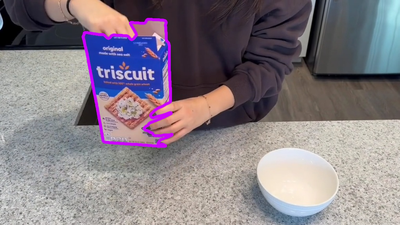
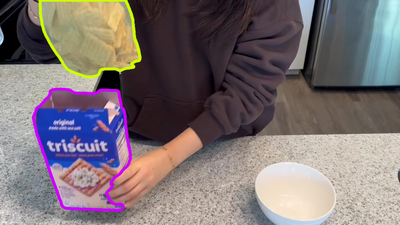
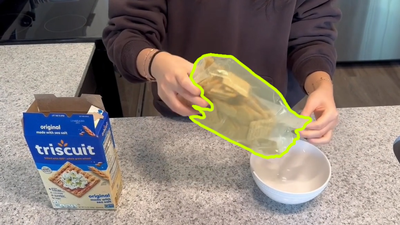
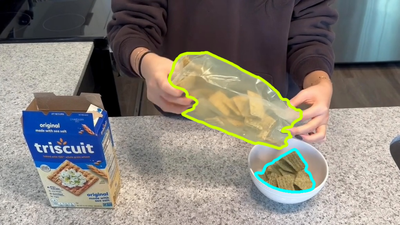
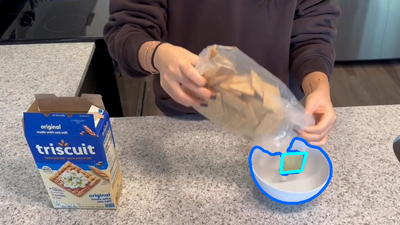
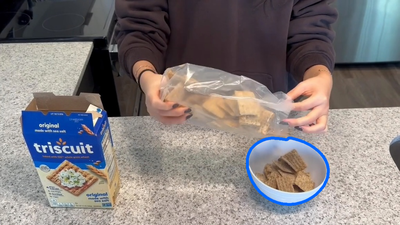
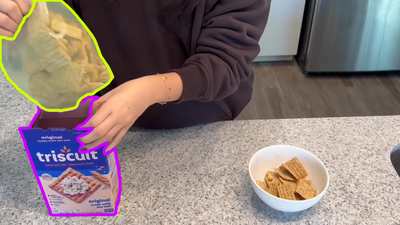
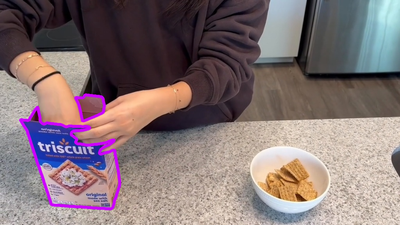

In [7]:
visualize_gt('crackers');


===== Ground Truth | Instance: put_keyboard_into_box =====
[frame= 16- 47]: seperate,pull_out | start: ['[2] keyboard box']                      | end: ['[1] keyboard tray', '[2] keyboard box']
[frame= 79- 88]: place,insert      | start: ['[0] keyboard', '[1] keyboard tray']     | end: ['[1] keyboard tray']
[frame=102-166]: insert            | start: ['[1] keyboard tray', '[2] keyboard box'] | end: ['[2] keyboard box']



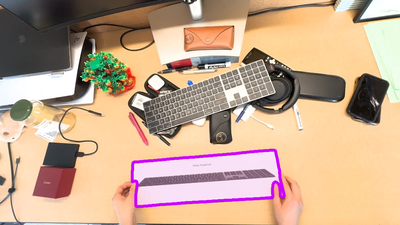
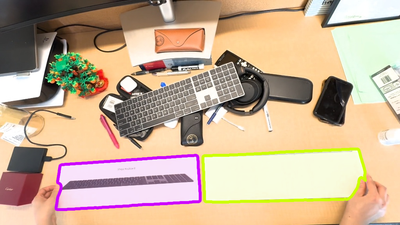
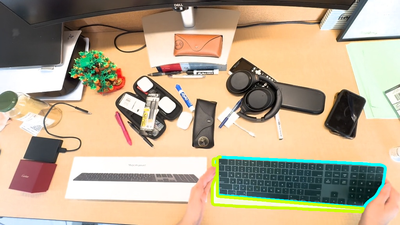
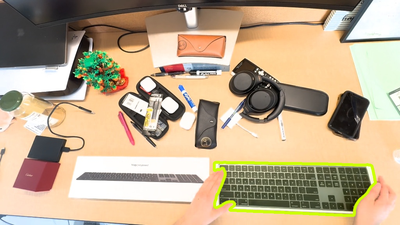
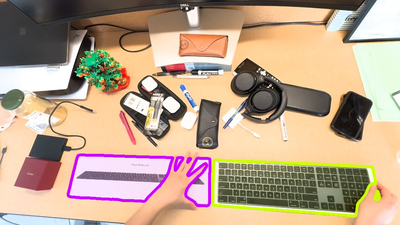
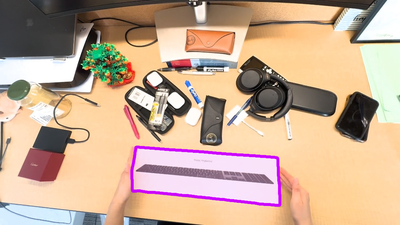

In [8]:
visualize_gt('put_keyboard_into_box');


===== Ground Truth | Instance: swap_sunglasses =====
[frame= 18- 46]: remove,take_out  | start: ['[0] sunglasses case']                         | end: ['[0] sunglasses case', '[4] microfiber cloth']
[frame= 60- 68]: remove,take_out  | start: ['[0] sunglasses case']                         | end: ['[0] sunglasses case', '[2] sunglasses']
[frame=112-139]: remove,take_out  | start: ['[1] sunglasses case']                         | end: ['[1] sunglasses case', '[3] sunglasses']
[frame=175-196]: insert,place,put | start: ['[1] sunglasses case', '[2] sunglasses']       | end: ['[1] sunglasses case']
[frame=210-249]: insert,place,put | start: ['[1] sunglasses case', '[4] microfiber cloth'] | end: ['[1] sunglasses case']
[frame=306-328]: insert,place,put | start: ['[0] sunglasses case', '[3] sunglasses']       | end: ['[0] sunglasses case']


[frame=18],[frame=46],[frame=60],[frame=68]
[frame=112],[frame=139],[frame=175],[frame=196]
[frame=210],[frame=249],[frame=306],[frame=328]

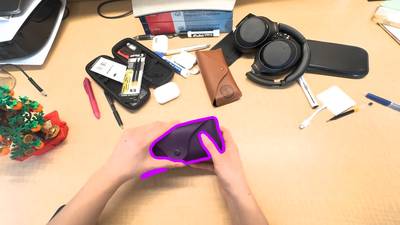
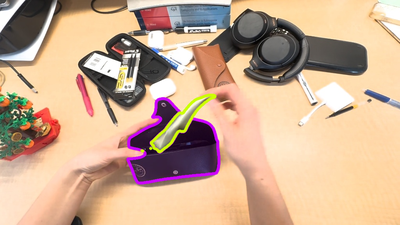
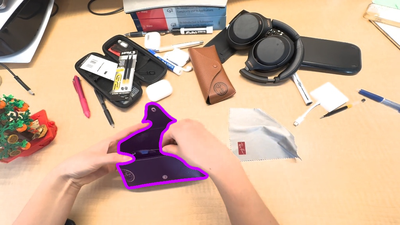
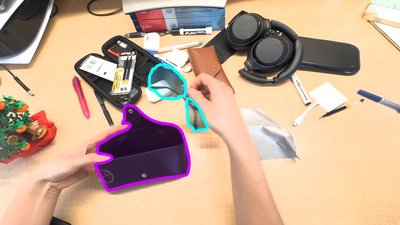
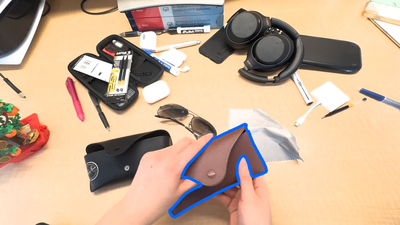
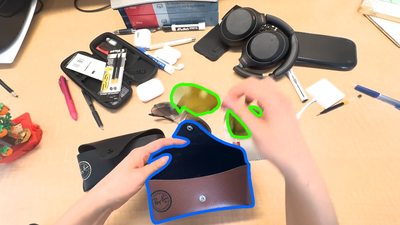
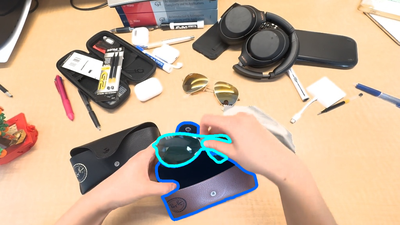
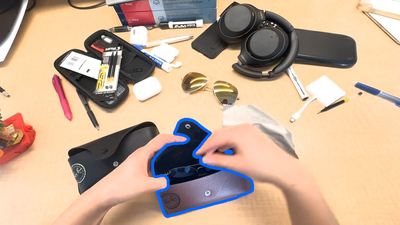
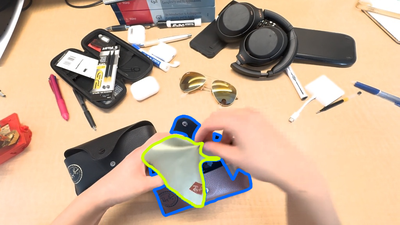
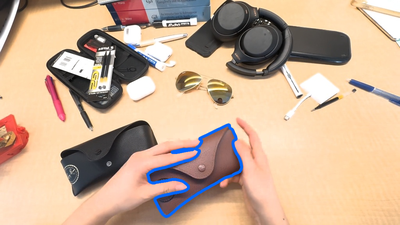
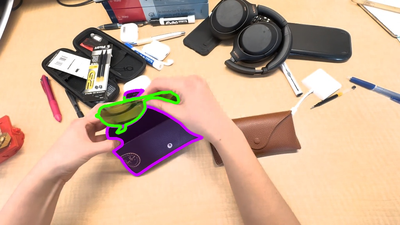
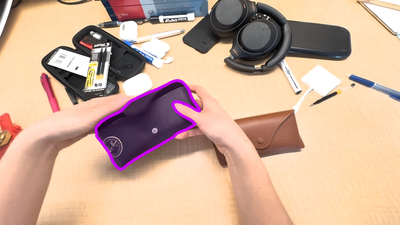

In [9]:
visualize_gt('swap_sunglasses');


===== Ground Truth | Instance: make_protein_shake =====
[frame= 38- 74]: pour                        | start: ['[0] bowl']                                | end: ['[0] bowl', '[1] protein powder']
[frame= 46- 77]: pour                        | start: ['[1] protein powder', '[2] shaker bottle'] | end: ['[2] shaker bottle']
[frame=115-118]: insert,drop,place           | start: ['[2] shaker bottle', '[5] blender ball']   | end: ['[2] shaker bottle']
[frame=168-211]: pour                        | start: ['[4] brita']                               | end: ['[4] brita', '[6] water']
[frame=261-284]: cap,close,screw_on,twist_on | start: ['[2] shaker bottle', '[3] shaker lid']     | end: ['[2] shaker bottle']



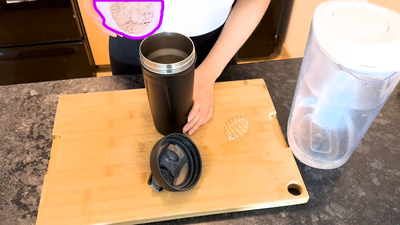
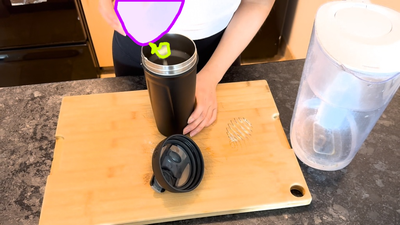
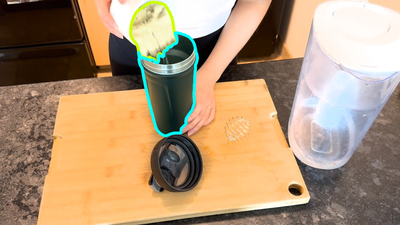
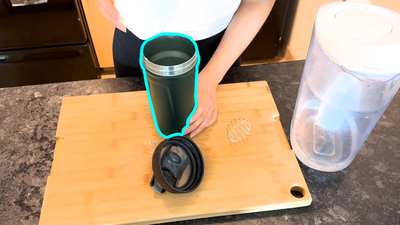
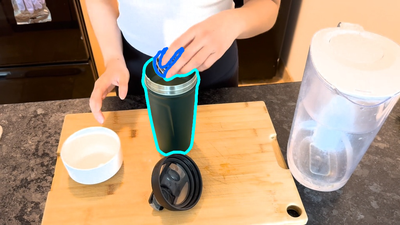
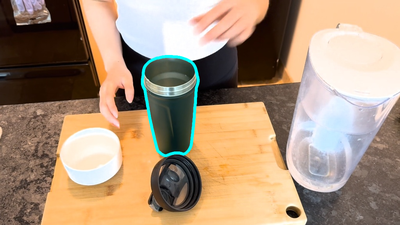
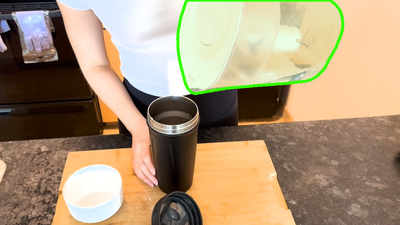
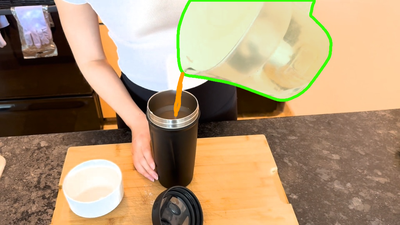
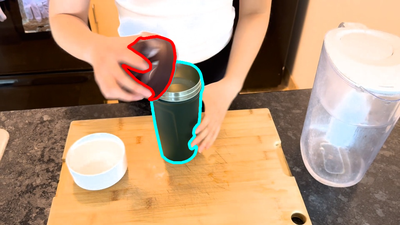
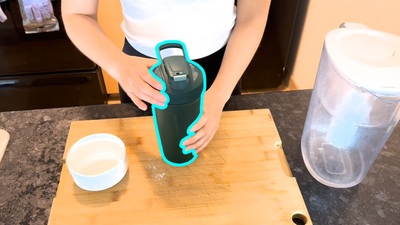

In [10]:
visualize_gt("make_protein_shake");